## **Subtask 4.2 -  train a fusion network** (sum)

Preparazione + Split stratificato

In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from glob import glob
from tensorflow import keras as K
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report


Import text vector

In [2]:
df = pd.read_csv("data/metadata_with_text_vectors.csv")
df

,id,gender,age,ptb,remarks,text_vector
0,1000,M,31,0,neutral result,[-6.77629948e-01 6.23885036e-01 -2.86139995e-...
1,1001,M,64,0,unremarkable,[-6.3992e-01 -1.6440e-01 2.9282e-01 -1.5618e-...
2,1002,M,35,0,routine exam,[-6.58964992e-01 -3.74590009e-01 -4.25999999e-...
3,1003,M,32,1,"STB,ATB,tuberculosis pleuritis",[-5.59461653e-01 7.61321560e-02 -1.71163321e-...
4,1004,M,2,1,secondary PTB in the bilateral upper field,[-6.58567488e-01 1.02602258e-01 -4.31476273e-...
...,...,...,...,...,...,...
694,1699,M,47,1,persistent rt pleural peel with some interval ...,[-7.34632254e-01 2.23481789e-01 -1.55677304e-...
695,1700,F,30,0,un-alarming,[-8.35789979e-01 1.56095996e-01 2.07589984e-...
696,1701,F,44,0,routine exam,[-6.58964992e-01 -3.74590009e-01 -4.25999999e-...
697,1702,F,30,1,left pleural effusion; best seen on lateral vi...,[-7.44324207e-01 1.61329776e-01 -1.88010558e-...


In [3]:
print(df["text_vector"].iloc[0])

[-6.77629948e-01  6.23885036e-01 -2.86139995e-01  1.61835000e-01
 -3.30379993e-01  1.86754495e-01 -3.50785017e-01  1.80064991e-01
  4.64829981e-01  1.73689997e+00 -3.53264987e-01  2.51129985e-01
  7.42549971e-02 -8.61829966e-02  5.60990013e-02  5.48149981e-02
 -8.87049921e-03  1.72860003e+00 -6.77924991e-01  9.84840021e-02
  1.46925002e-01 -8.37614983e-02  7.80250132e-03  5.73949963e-02
  2.70810008e-01  3.45309973e-01 -8.34290013e-02 -2.90164985e-02
 -1.85389996e-01  3.46285030e-02  6.79354966e-02  8.03899914e-02
  5.60364984e-02 -3.14486980e-01  1.48485005e-01  4.50245023e-01
  1.76249966e-02 -1.80065006e-01 -2.32334495e-01 -5.60384989e-01
 -1.74411997e-01 -1.62746996e-01  2.03188002e-01 -5.01815006e-02
  2.15386510e-01 -3.08164001e-01  1.65529996e-01  4.29759979e-01
 -8.23500007e-03 -4.82504994e-01 -2.89775014e-01  8.46170038e-02
  7.12998211e-04 -2.21035004e-01  6.68900087e-02  2.05323994e-01
 -1.27639994e-01  1.40204996e-01 -1.93622991e-01 -2.63279974e-02
 -1.08944997e-01  6.38419

In [4]:
X_text = np.vstack(df["text_vector"].str.strip("[]").str.split().apply(np.float32))
X_text

array([[-0.67762995,  0.62388504, -0.28614   , ..., -0.08726001,
         0.15876749, -0.034165  ],
       [-0.63992   , -0.1644    ,  0.29282   , ..., -0.20086   ,
         0.07254   , -0.29882   ],
       [-0.658965  , -0.37459   , -0.426     , ...,  0.38332   ,
         0.39714998, -0.227875  ],
       ...,
       [-0.658965  , -0.37459   , -0.426     , ...,  0.38332   ,
         0.39714998, -0.227875  ],
       [-0.7443242 ,  0.16132978, -0.18801056, ..., -0.12297931,
        -0.01434448,  0.16458756],
       [-0.6469567 ,  0.36637667,  0.07224   , ..., -0.46439335,
         0.24408334, -0.2009    ]], dtype=float32)

In [5]:
IMG_DIR = "data/images/segmented_all"

# loads and sorted all filename of segmented img (699)
img_paths = sorted(glob(os.path.join(IMG_DIR, "*.png")))
print(f"Immagini segmentate trovate: {len(img_paths)}")

# ID img/patient from filename
img_ids = [int(os.path.splitext(os.path.basename(p))[0]) for p in img_paths]

# label
y_label = (df.set_index("id").loc[img_ids]["ptb"].values.astype(np.float32))

# loads images (0..255, float32)
images = []
for p in img_paths:
    img = Image.open(p).convert("RGB")
    images.append(np.array(img, dtype=np.float32))

X_img = np.stack(images, axis=0)

print("X_img:", X_img.shape)
print("X_text:", X_text.shape)
print("y_label:", y_label.shape)
print("Class balance (mean y_label):", np.mean(y_label))

# split stratificato
X_img_train, X_img_val, X_text_train, X_text_val, y_train, y_val = train_test_split(X_img, X_text, y_label, test_size=0.2, random_state=42, stratify=y_label)

dataset= {
        "train_images": X_img_train,
        "val_images":   X_img_val,
        "train_text":   X_text_train,
        "val_text":     X_text_val,
        "train_y":      y_train,
        "val_y":        y_val
    }


Immagini segmentate trovate: 699
X_img: (699, 224, 224, 3)
X_text: (699, 300)
y_label: (699,)
Class balance (mean y_label): 0.48640916


#### Selected QUESTION: *Do the text features help improve performances with respect to not using them?* (with sum)

##### VGG Pre-trained + Text features
The pipeline followed is the following:
```
Img → VGG → feature_img      ┐
                             ├→ sum → Dense → PTB
Text → Dense → feature_txt   ┘
```


In [6]:
def build_fusion_model():
    # input segmented images
    img_input = K.layers.Input(shape=X_img_train.shape[1:], name="img_input")
    # VGG preprocessing (required when using ImageNet weights)
    x = K.applications.vgg16.preprocess_input(img_input)
    # VGG16 pretrained
    vgg = K.applications.VGG16(weights="imagenet", include_top=False, input_tensor=x)
    vgg.trainable = False
    # convert feature maps into a feature vector
    x = K.layers.Flatten()(vgg.output)
    # small dense layer to adapt image features
    x = K.layers.Dense(32, activation="relu")(x)

    img_features = x

    # text input (pre-extracted embedding)
    text_input = K.layers.Input(shape=(X_text_train.shape[1],), name="text_input")
    t = K.layers.Dense(32, activation="relu", name="text_dense")(text_input)
    text_features = t

    # ---- fusion: SUM image and text representations ----
    fusion = K.layers.Add(name="fusion_sum")([img_features, text_features])
    z = K.layers.Dense(32, activation="relu", name="fusion_dense")(fusion)
    output = K.layers.Dense(1, activation="sigmoid", name="ptb_output")(z)

    model_img_txt = K.models.Model(
        inputs=[img_input, text_input],
        outputs=output,
        name="VGG16_text_fusion"
    )

    return model_img_txt
model_img_txt = build_fusion_model()
model_img_txt.summary()

Model: "VGG16_text_fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ img_input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ img_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ img_input[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ img_input[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 224, 224,  │      1,792 │ add[0][0]         │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 224, 224,  │     36,928 │ block1_conv1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 112, 112,  │          0 │ block1_conv2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 112, 112,  │     73,856 │ block1_pool[0][0] │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv2        │ (None, 112, 112,  │    147,584 │ block2_conv1[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 56, 56,    │          0 │ block2_conv2[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv1        │ (None, 56, 56,    │    295,168 │ block2_pool[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv2        │ (None, 56, 56,    │    590,080 │ block3_conv1[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv3        │ (None, 56, 56,    │    590,080 │ block3_conv2[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_pool         │ (None, 28, 28,    │          0 │ block3_conv3[0][… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv1        │ (None, 28, 28,    │  1,180,160 │ block3_pool[0][0

 Total params: 15,528,257 (59.24 MB)

 Trainable params: 813,569 (3.10 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

#### VGG Pretrained only img

In [7]:
def build_img_model():
    img_input = K.layers.Input(
        shape=X_img_train.shape[1:],
        name="img_input"
    )

    x = K.applications.vgg16.preprocess_input(img_input)

    vgg = K.applications.VGG16(weights="imagenet", include_top=False, input_tensor=x)
    vgg.trainable = False

    x = K.layers.Flatten()(vgg.output)
    x = K.layers.Dense(32, activation="relu")(x)

    output = K.layers.Dense(1, activation="sigmoid")(x)

    model_img = K.models.Model(
        inputs=img_input,
        outputs=output,
        name="image_only_vgg16"
    )
    return model_img

model_img = build_img_model()
model_img.summary()


Model: "image_only_vgg16"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ img_input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 224, 224)  │          0 │ img_input[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 224, 224)  │          0 │ img_input[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 224, 224)  │          0 │ img_input[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 224, 224,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 224, 224,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 224, 224,  │      1,792 │ add_1[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 224, 224,  │     36,928 │ block1_conv1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 112, 112,  │          0 │ block1_conv2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 112, 112,  │     73,856 │ block1_pool[0][0] │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv2        │ (None, 112, 112,  │    147,584 │ block2_conv1[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 56, 56,    │          0 │ block2_conv2[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv1        │ (None, 56, 56,    │    295,168 │ block2_pool[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv2        │ (None, 56, 56,    │    590,080 │ block3_conv1[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv3        │ (None, 56, 56,    │    590,080 │ block3_conv2[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_pool         │ (None, 28, 28,    │          0 │ block3_conv3[0][… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 15,517,569 (59.19 MB)

 Trainable params: 802,881 (3.06 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

#### Training and evaluation

In [8]:
train_results = []

def train_model(model, model_name, use_text=True, max_epoch=40, batch_size=8):
    model.compile(
        optimizer=K.optimizers.Adam(learning_rate=1e-5),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            K.metrics.AUC(name="auc"),
            K.metrics.Precision(name="precision"),
            K.metrics.Recall(name="recall")
        ]
    )

    # Save only the weights of the model achieving the highest validation IoU
    checkpoint_cb = K.callbacks.ModelCheckpoint(
        f"models/{model_name}.weights.h5",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    )

    # decreases the learning rate when performance stops improving
    reduce_cb = K.callbacks.ReduceLROnPlateau(
        monitor="val_auc",
        mode="max",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )

    # stops training when the model no longer improves
    early_cb = K.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )

    # --- training ---
    if use_text:
        x_tmp = [dataset["train_images"], dataset["train_text"]]
        val_data = ([dataset["val_images"], dataset["val_text"]], dataset["val_y"])
    else:
        x_tmp = dataset["train_images"]
        val_data = (dataset["val_images"], dataset["val_y"])


    history = model.fit(
        x=x_tmp,
        y=dataset["train_y"],
        validation_data=val_data,
        epochs=max_epoch,
        batch_size=batch_size,
        callbacks=[checkpoint_cb, reduce_cb, early_cb],
        verbose=1
    )

    best_val_auc = float(np.max(history.history["val_auc"]))
    best_epoch   = int(np.argmax(history.history["val_auc"]))

    print(f"[{model_name}] Best val AUC = {best_val_auc:.4f} at epoch {best_epoch}")

    train_results.append({
        "model": model_name,
        "use_text": use_text,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,
        "weights_path": f"models/{model_name}.weights.h5"
    })

    return history


##### Modello 1: Fusion

In [9]:
history_fusion = train_model(
    model=model_img_txt,
    model_name="fusion_vgg16",
    use_text=True
)
#1h4m

Epoch 1/40
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5387 - auc: 0.5715 - loss: 1.0976 - precision: 0.5163 - recall: 0.6160
Epoch 1: val_auc improved from -inf to 0.66187, saving model to models/fusion_vgg16.weights.h5
70/70 ━━━━━━━━━━━━━━━━━━━━ 105s 1s/step - accuracy: 0.5390 - auc: 0.5716 - loss: 1.0955 - precision: 0.5167 - recall: 0.6149 - val_accuracy: 0.6357 - val_auc: 0.6619 - val_loss: 0.8314 - val_precision: 0.6604 - val_recall: 0.5147 - learning_rate: 1.0000e-05
Epoch 2/40
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 982ms/step - accuracy: 0.6699 - auc: 0.7322 - loss: 0.6274 - precision: 0.6513 - recall: 0.6299
Epoch 2: val_auc improved from 0.66187 to 0.71119, saving model to models/fusion_vgg16.weights.h5
70/70 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.6703 - auc: 0.7327 - loss: 0.6269 - precision: 0.6519 - recall: 0.6304 - val_accuracy: 0.6857 - val_auc: 0.7112 - val_loss: 0.7678 - val_precision: 0.7500 - val_recall: 0.5294 - learning_rate: 1.0000e-05
Epoch 3/40
70/70 ━━━━

##### Modello 2: Img only

In [10]:
history_img = train_model(
    model=model_img,
    model_name="image_only_vgg16",
    use_text=False
)
#1h6m

Epoch 1/40
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5427 - auc: 0.6193 - loss: 1.6130 - precision: 0.5111 - recall: 0.5337
Epoch 1: val_auc improved from -inf to 0.70813, saving model to models/image_only_vgg16.weights.h5
70/70 ━━━━━━━━━━━━━━━━━━━━ 128s 2s/step - accuracy: 0.5430 - auc: 0.6194 - loss: 1.6120 - precision: 0.5117 - recall: 0.5337 - val_accuracy: 0.6286 - val_auc: 0.7081 - val_loss: 1.1696 - val_precision: 0.6739 - val_recall: 0.4559 - learning_rate: 1.0000e-05
Epoch 2/40
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6720 - auc: 0.7579 - loss: 0.8312 - precision: 0.6817 - recall: 0.6180
Epoch 2: val_auc improved from 0.70813 to 0.76420, saving model to models/image_only_vgg16.weights.h5
70/70 ━━━━━━━━━━━━━━━━━━━━ 116s 2s/step - accuracy: 0.6722 - auc: 0.7578 - loss: 0.8322 - precision: 0.6816 - recall: 0.6185 - val_accuracy: 0.7000 - val_auc: 0.7642 - val_loss: 0.9427 - val_precision: 0.7407 - val_recall: 0.5882 - learning_rate: 1.0000e-05
Epoch 3/40
70/7

### TESTING and evaluation

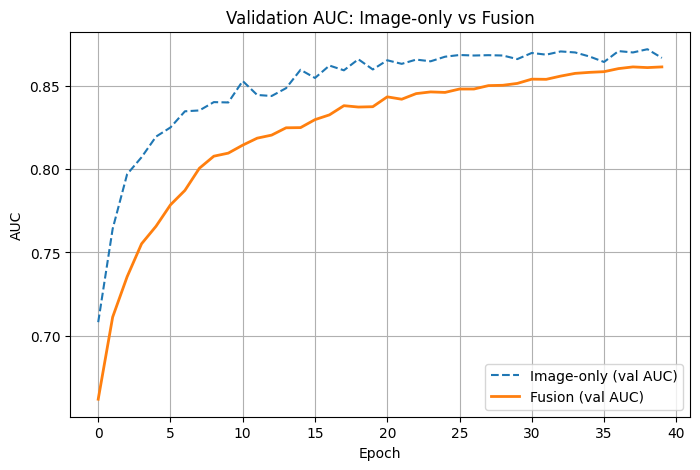

In [11]:
import matplotlib.pyplot as plt

def plot_auc_comparison(history_img, history_fusion):
    plt.figure(figsize=(8,5))

    plt.plot(
        history_img.history["val_auc"],
        label="Image-only (val AUC)",
        linestyle="--"
    )

    plt.plot(
        history_fusion.history["val_auc"],
        label="Fusion (val AUC)",
        linewidth=2
    )

    plt.xlabel("Epoch")
    plt.ylabel("AUC")
    plt.title("Validation AUC: Image-only vs Fusion")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_auc_comparison(history_img, history_fusion)


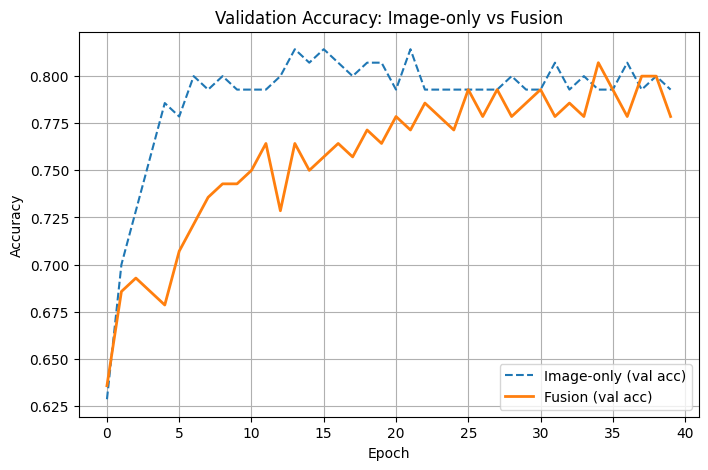

In [12]:
def plot_accuracy_comparison(history_img, history_fusion):
    plt.figure(figsize=(8,5))

    plt.plot(
        history_img.history["val_accuracy"],
        label="Image-only (val acc)",
        linestyle="--"
    )

    plt.plot(
        history_fusion.history["val_accuracy"],
        label="Fusion (val acc)",
        linewidth=2
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Validation Accuracy: Image-only vs Fusion")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_accuracy_comparison(history_img, history_fusion)


In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

def plot_confusion_percent(model, x_val, y_val, title):
    y_prob = model.predict(x_val)
    y_pred = (y_prob > 0.5).astype(int).ravel()

    cm = confusion_matrix(y_val, y_pred)
    cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100
    labels = ["non-PTB", "PTB"]

    fig, ax = plt.subplots(figsize=(4,4))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_percent,
        display_labels=labels
    )
    disp.plot(
        cmap="Blues",
        values_format=".1f",
        ax=ax
    )

    ax.set_title(title + " (%)")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    plt.show()


5/5 ━━━━━━━━━━━━━━━━━━━━ 15s 3s/step


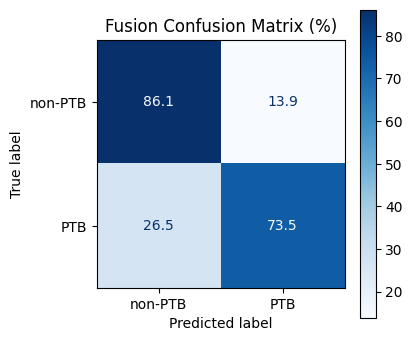

In [24]:
plot_confusion_percent(
    model_img_txt,
    [dataset["val_images"], dataset["val_text"]],
    dataset["val_y"],
    "Fusion Confusion Matrix"
)


5/5 ━━━━━━━━━━━━━━━━━━━━ 25s 5s/step


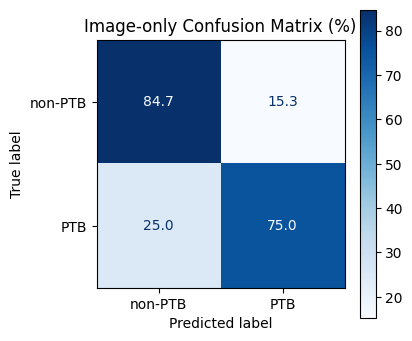

In [25]:
plot_confusion_percent(
    model_img,
    dataset["val_images"],
    dataset["val_y"],
    "Image-only Confusion Matrix"
)


In [18]:
from sklearn.metrics import classification_report

def print_report(model, x_val, y_val, title):
    y_prob = model.predict(x_val)
    y_pred = (y_prob > 0.5).astype(int).ravel()

    print(title)
    print(classification_report(y_val, y_pred, digits=3))

print_report(
    model_img,
    dataset["val_images"],
    dataset["val_y"],
    "IMAGE-ONLY"
)

print_report(
    model_img_txt,
    [dataset["val_images"], dataset["val_text"]],
    dataset["val_y"],
    "FUSION"
)


5/5 ━━━━━━━━━━━━━━━━━━━━ 16s 3s/step
IMAGE-ONLY
              precision    recall  f1-score   support

         0.0      0.782     0.847     0.813        72
         1.0      0.823     0.750     0.785        68

    accuracy                          0.800       140
   macro avg      0.802     0.799     0.799       140
weighted avg      0.802     0.800     0.799       140

5/5 ━━━━━━━━━━━━━━━━━━━━ 18s 3s/step
FUSION
              precision    recall  f1-score   support

         0.0      0.775     0.861     0.816        72
         1.0      0.833     0.735     0.781        68

    accuracy                          0.800       140
   macro avg      0.804     0.798     0.799       140
weighted avg      0.803     0.800     0.799       140



5/5 ━━━━━━━━━━━━━━━━━━━━ 16s 3s/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 17s 3s/step


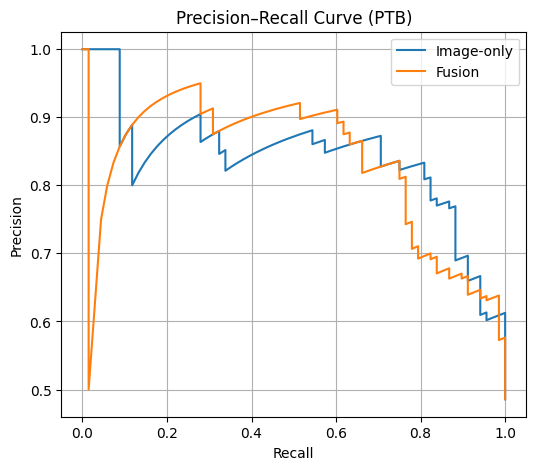

In [19]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

def plot_pr_curve(model, x_val, y_val, label):
    y_prob = model.predict(x_val).ravel()
    precision, recall, _ = precision_recall_curve(y_val, y_prob)

    plt.plot(recall, precision, label=label)

plt.figure(figsize=(6,5))
plot_pr_curve(model_img, dataset["val_images"], dataset["val_y"], "Image-only")
plot_pr_curve(model_img_txt, [dataset["val_images"], dataset["val_text"]], dataset["val_y"], "Fusion")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve (PTB)")
plt.legend()
plt.grid()
plt.show()
